
**Name:** kamran khan 
**Roll No:** BSDS030
**Course:** Data Visualization (Week 3)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb
from skimage.color import rgb2lab
from IPython.display import display

DATA = Path('/mnt/data')
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def finish(fig, filename=None):
    if filename:
        fig.savefig(DATA / filename, dpi=300, bbox_inches='tight')
    plt.show()

## Part A — Rebuild and diagnose nine published claims

Each case reproduces the supplied recipe first, then plots a more defensible view. The explanation identifies the mechanism in the data rather than relying on a generic objection.

### 1. Helmet grade and head-injury rate

The supplied recipe aggregates injuries and trips by helmet grade and plots injuries per 1,000 trips.

,injuries,trips,mean_speed,mean_experience,injuries_per_1000_trips
helmet_grade,,,,,
Standard,129,60000,30.22,31.50,2.15
Premium,216,40000,66.95,31.42,5.40


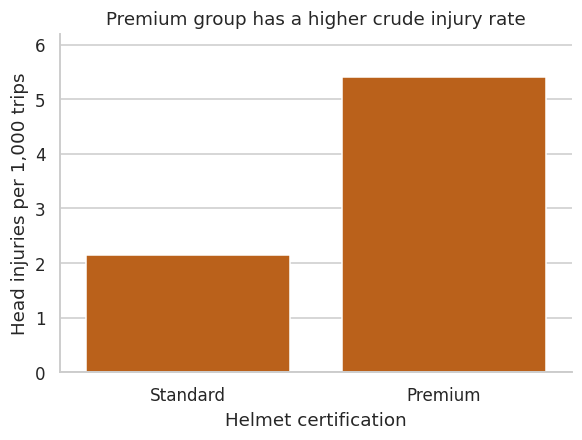

In [2]:
helmet = pd.read_csv(DATA / 'case01_helmet_rickshaw.csv')
helmet_summary = helmet.groupby('helmet_grade', sort=False).agg(
    injuries=('head_injuries','sum'), trips=('trips','sum'),
    mean_speed=('avg_speed_kph','mean'), mean_experience=('months_experience','mean'))
helmet_summary['injuries_per_1000_trips'] = 1000 * helmet_summary.injuries / helmet_summary.trips
display(helmet_summary.round(2))
fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(data=helmet_summary.reset_index(), x='helmet_grade', y='injuries_per_1000_trips',
            color='#D55E00', ax=ax)
ax.set_ylim(0, 6.2); ax.set_xlabel('Helmet certification'); ax.set_ylabel('Head injuries per 1,000 trips')
ax.set_title('Premium group has a higher crude injury rate')
finish(fig)

**Invited conclusion:** premium-certified helmets are associated with more head injuries. **Decoy objection:** a zero baseline is not the issue here; the first chart already starts at zero, and rates use trips as the denominator. **Mechanism:** road type and riding speed differ sharply between groups. Premium riders completed 34,000 motorway trips versus only 2,000 for Standard riders; mean speed was about 67 versus 30 km/h. Within each road type, the Premium rate is lower (Motorway 6 vs 8, City arterial 2.2 vs 3, Inner-city 1 vs 1.39 injuries per 1,000 trips). The crude comparison is confounded by exposure mix. The stratified chart below shows the comparison within road types.

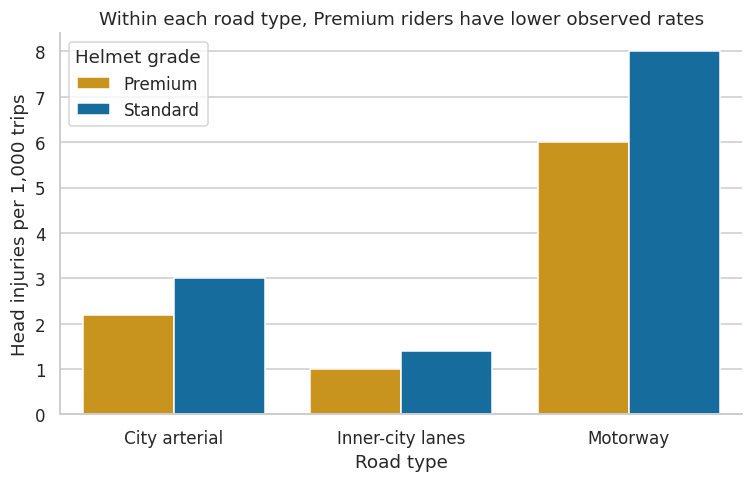

In [3]:
road = helmet.groupby(['road_type','helmet_grade']).agg(injuries=('head_injuries','sum'), trips=('trips','sum')).reset_index()
road['rate'] = 1000 * road.injuries / road.trips
fig, ax = plt.subplots(figsize=(8,4.5))
sns.barplot(data=road, x='road_type', y='rate', hue='helmet_grade',
            palette={'Standard':'#0072B2','Premium':'#E69F00'}, ax=ax)
ax.set_ylabel('Head injuries per 1,000 trips'); ax.set_xlabel('Road type')
ax.set_title('Within each road type, Premium riders have lower observed rates')
ax.legend(title='Helmet grade'); finish(fig)

### 2. Chai sales and quiz failures

The recipe uses monthly cups sold and quiz failures, with a least-squares fit and Pearson correlation.

Pearson r = 0.982


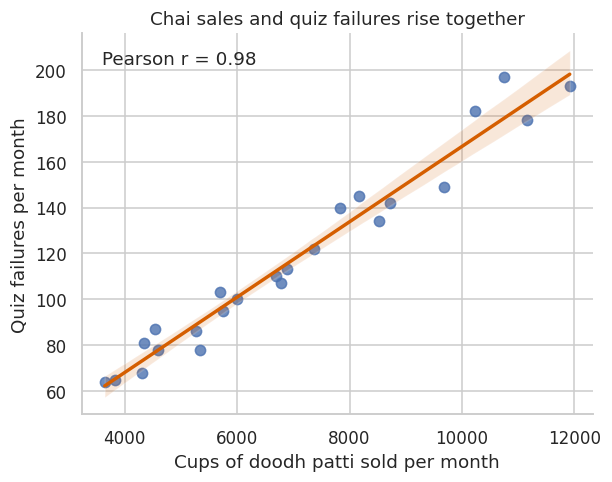

In [4]:
chai = pd.read_csv(DATA / 'case02_chai_quizzes.csv')
r = chai['cups_doodh_patti_sold'].corr(chai['quiz_failures'])
print(f'Pearson r = {r:.3f}')
fig, ax = plt.subplots(figsize=(6,4.5))
sns.regplot(data=chai, x='cups_doodh_patti_sold', y='quiz_failures',
            scatter_kws={'s':45, 'alpha':.8}, line_kws={'color':'#D55E00'}, ax=ax)
ax.text(.04,.92,f'Pearson r = {r:.2f}',transform=ax.transAxes)
ax.set_title('Chai sales and quiz failures rise together')
ax.set_xlabel('Cups of doodh patti sold per month'); ax.set_ylabel('Quiz failures per month')
finish(fig)

**Invited conclusion:** more chai sales predict more failures. **Decoy objection:** the strong correlation is real (r ≈ 0.98), so dismissing it as a weak association is not supported. **Mechanism:** enrolment is a shared scale variable: students enrolled correlate 0.997 with cups sold and 0.977 with quiz failures. More students create both more canteen purchases and more opportunities for failures. A useful redesign compares rates per 1,000 enrolled students rather than raw counts.

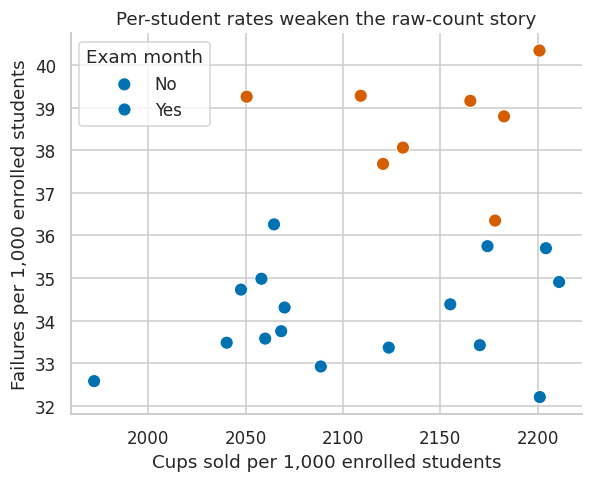

In [5]:
chai['cups_per_1000_students'] = 1000*chai.cups_doodh_patti_sold/chai.students_enrolled
chai['failures_per_1000_students'] = 1000*chai.quiz_failures/chai.students_enrolled
fig, ax = plt.subplots(figsize=(6,4.5))
sns.scatterplot(data=chai, x='cups_per_1000_students', y='failures_per_1000_students',
                hue='is_exam_month', palette={0:'#0072B2',1:'#D55E00'}, s=75, ax=ax)
ax.set_title('Per-student rates weaken the raw-count story')
ax.set_xlabel('Cups sold per 1,000 enrolled students'); ax.set_ylabel('Failures per 1,000 enrolled students')
ax.legend(title='Exam month', labels=['No','Yes']); finish(fig)

### 3. Lahore AQI before and after the action-plan marker

The original recipe averages all available station rows by date, with a zero baseline and a marker at day 61.

Before mean = 202.1; after mean = 137.2; change = -32.1%


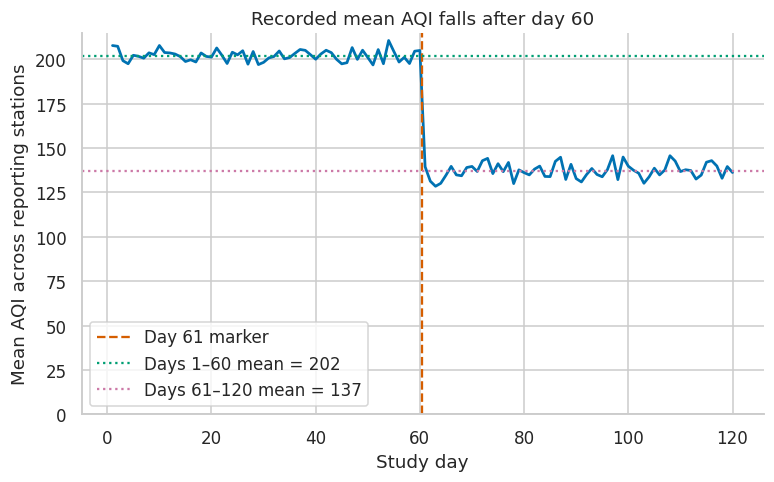

In [6]:
aqi = pd.read_csv(DATA / 'case03_aqi_monitors.csv')
aqi['date'] = pd.to_datetime(aqi['date'])
daily_aqi = aqi.groupby('date', as_index=False).aqi.mean().sort_values('date')
daily_aqi['day'] = np.arange(1, len(daily_aqi)+1)
before = daily_aqi.loc[daily_aqi.day<=60,'aqi'].mean()
after = daily_aqi.loc[daily_aqi.day>60,'aqi'].mean()
print(f'Before mean = {before:.1f}; after mean = {after:.1f}; change = {(after/before-1)*100:.1f}%')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.plot(daily_aqi.day, daily_aqi.aqi, color='#0072B2', lw=1.8)
ax.axvline(60.5, color='#D55E00', ls='--', label='Day 61 marker')
ax.axhline(before, color='#009E73', ls=':', label=f'Days 1–60 mean = {before:.0f}')
ax.axhline(after, color='#CC79A7', ls=':', label=f'Days 61–120 mean = {after:.0f}')
ax.set_ylim(bottom=0); ax.set_xlabel('Study day'); ax.set_ylabel('Mean AQI across reporting stations')
ax.set_title('Recorded mean AQI falls after day 60')
ax.legend(); finish(fig)

**Invited conclusion:** the plan caused a 32% AQI reduction. **Decoy objection:** the zero baseline is explicitly required and used, so axis truncation is not the mechanism. **Mechanism:** station coverage changes. All 1,320 station-day rows before the marker have AQI values; after it, 540 of 1,320 are missing. `mean()` silently averages only reporting stations, so the two periods are not based on equivalent coverage. The line below adds the daily number of available readings; the decline is an observed mean, not proof of a policy effect.

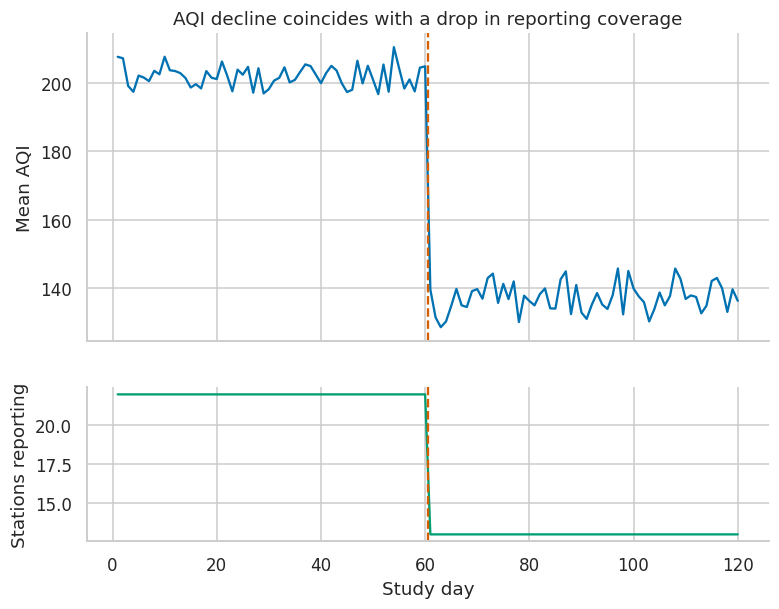

In [7]:
daily_n = aqi.groupby('date').aqi.count().rename('n_reporting').reset_index()
plot_aqi = daily_aqi.merge(daily_n, on='date')
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(8,6),sharex=True,gridspec_kw={'height_ratios':[2,1]})
ax1.plot(plot_aqi.day, plot_aqi.aqi, color='#0072B2')
ax1.axvline(60.5,color='#D55E00',ls='--')
ax1.set_ylabel('Mean AQI'); ax1.set_title('AQI decline coincides with a drop in reporting coverage')
ax2.plot(plot_aqi.day, plot_aqi.n_reporting, color='#009E73')
ax2.axvline(60.5,color='#D55E00',ls='--')
ax2.set_ylabel('Stations reporting'); ax2.set_xlabel('Study day')
finish(fig)

### 4. Department quartet: identical summary statistics

Produce the requested table, then plot each department's raw paired observations.

,n,mean_hours,mean_score,sd_hours,sd_score,pearson_r,slope
department,,,,,,,
Architecture,11,18.0,14.501,6.633,2.031,0.817,0.25
Business Administration,11,18.0,14.501,6.633,2.032,0.816,0.25
Computer Science,11,18.0,14.501,6.633,2.032,0.816,0.25
Electrical Engineering,11,18.0,14.500,6.633,2.030,0.816,0.25


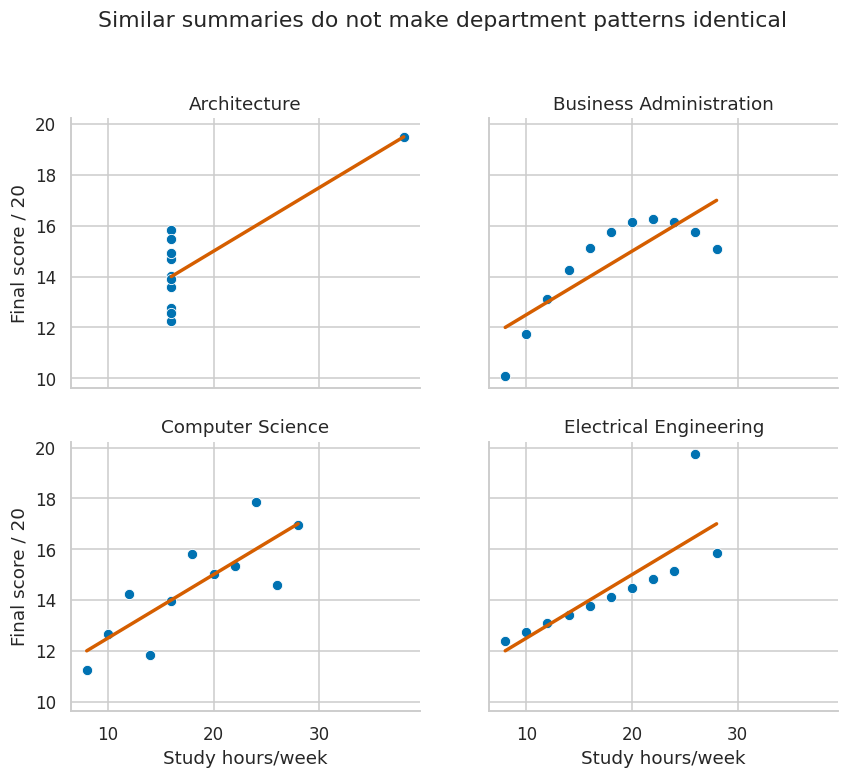

In [8]:
quartet = pd.read_csv(DATA / 'case04_quartet_depts.csv')
def regression_slope(g, x, y):
    return np.polyfit(g[x], g[y], 1)[0]
rows=[]
for name,g in quartet.groupby('department', sort=True):
    rows.append({'department':name,'n':len(g),'mean_hours':g.study_hours_per_week.mean(),
                 'mean_score':g.final_score_out_of_20.mean(),'sd_hours':g.study_hours_per_week.std(),
                 'sd_score':g.final_score_out_of_20.std(),
                 'pearson_r':g.study_hours_per_week.corr(g.final_score_out_of_20),
                 'slope':regression_slope(g,'study_hours_per_week','final_score_out_of_20')})
quartet_stats=pd.DataFrame(rows).set_index('department')
display(quartet_stats.round(3))
fig, axes = plt.subplots(2,2,figsize=(9,7),sharex=True,sharey=True)
for ax,(name,g) in zip(axes.flat,quartet.groupby('department',sort=True)):
    sns.scatterplot(data=g,x='study_hours_per_week',y='final_score_out_of_20',s=45,ax=ax,color='#0072B2')
    sns.regplot(data=g,x='study_hours_per_week',y='final_score_out_of_20',scatter=False,ci=None,ax=ax,color='#D55E00')
    ax.set_title(name); ax.set_xlabel('Study hours/week'); ax.set_ylabel('Final score / 20')
fig.suptitle('Similar summaries do not make department patterns identical',y=1.02)
finish(fig)

**Invited conclusion:** equal means and correlations justify equal funding. **Decoy objection:** small sample size is not the key issue; all four groups have n = 11 by design. **Mechanism:** aggregate statistics hide different point arrangements and outliers. The small differences in the reported moments do not establish identical learning patterns. The four scatter panels preserve the paired observations that the summary table discards; funding decisions need more than matching means and correlations.

### 5. Five cohorts with matching summary statistics

shape_name,ring,star,straight line,the letter X,two clusters
n,180.000,180.000,180.000,180.000,180.000
mean_hours,48.000,48.000,48.000,48.000,48.000
mean_score,63.000,63.000,63.000,63.000,63.000
sd_hours,12.033,12.033,12.033,12.033,12.033
sd_score,15.042,15.042,15.042,15.042,15.042
pearson_r,0.420,0.420,0.420,0.420,0.420


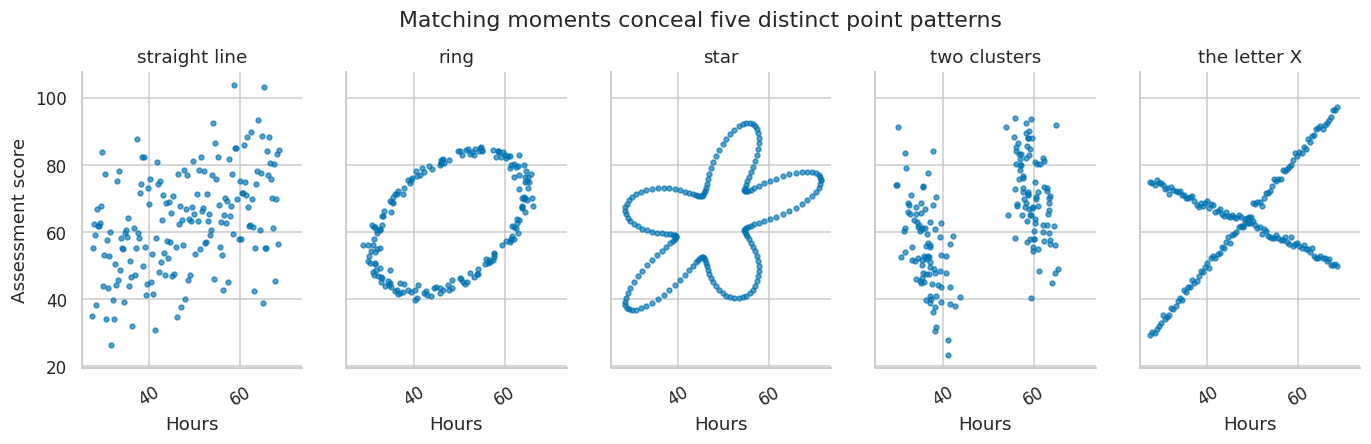

In [9]:
shapes = pd.read_csv(DATA / 'case05_same_stats_shapes.csv')
shape_stats = shapes.groupby('shape_name').agg(
    n=('hours_on_platform','size'), mean_hours=('hours_on_platform','mean'),
    mean_score=('assessment_score','mean'), sd_hours=('hours_on_platform','std'),
    sd_score=('assessment_score','std'),
    pearson_r=('hours_on_platform',lambda x: x.corr(shapes.loc[x.index,'assessment_score']))).T
display(shape_stats.round(3))
fig, axes = plt.subplots(1,5,figsize=(15,3.5),sharex=True,sharey=True)
for ax,(name,g) in zip(axes,shapes.groupby('shape_name',sort=False)):
    ax.scatter(g.hours_on_platform,g.assessment_score,s=10,alpha=.65,color='#0072B2')
    ax.set_title(name); ax.set_xlabel('Hours')
    ax.tick_params(axis='x',labelrotation=30)
axes[0].set_ylabel('Assessment score')
fig.suptitle('Matching moments conceal five distinct point patterns',y=1.04)
finish(fig)

**Invited conclusion:** the five cohorts are statistically interchangeable because their means, standard deviations, and correlations match. **Decoy objection:** rounding does not explain the similarity; the full-precision statistics are deliberately almost identical. **Mechanism:** the datasets have different geometries (line, ring, star, X, and clusters) despite matching low-order summaries. The faceted scatterplots reveal structure that a table cannot show. The data should be investigated cohort by cohort before treating the groups as equivalent.

### 6. Correlation heatmap from the sensor matrix

Matrix shape: (20, 20)
creatinine–hba1c: 0.77
systolic–map_mmhg: 0.96


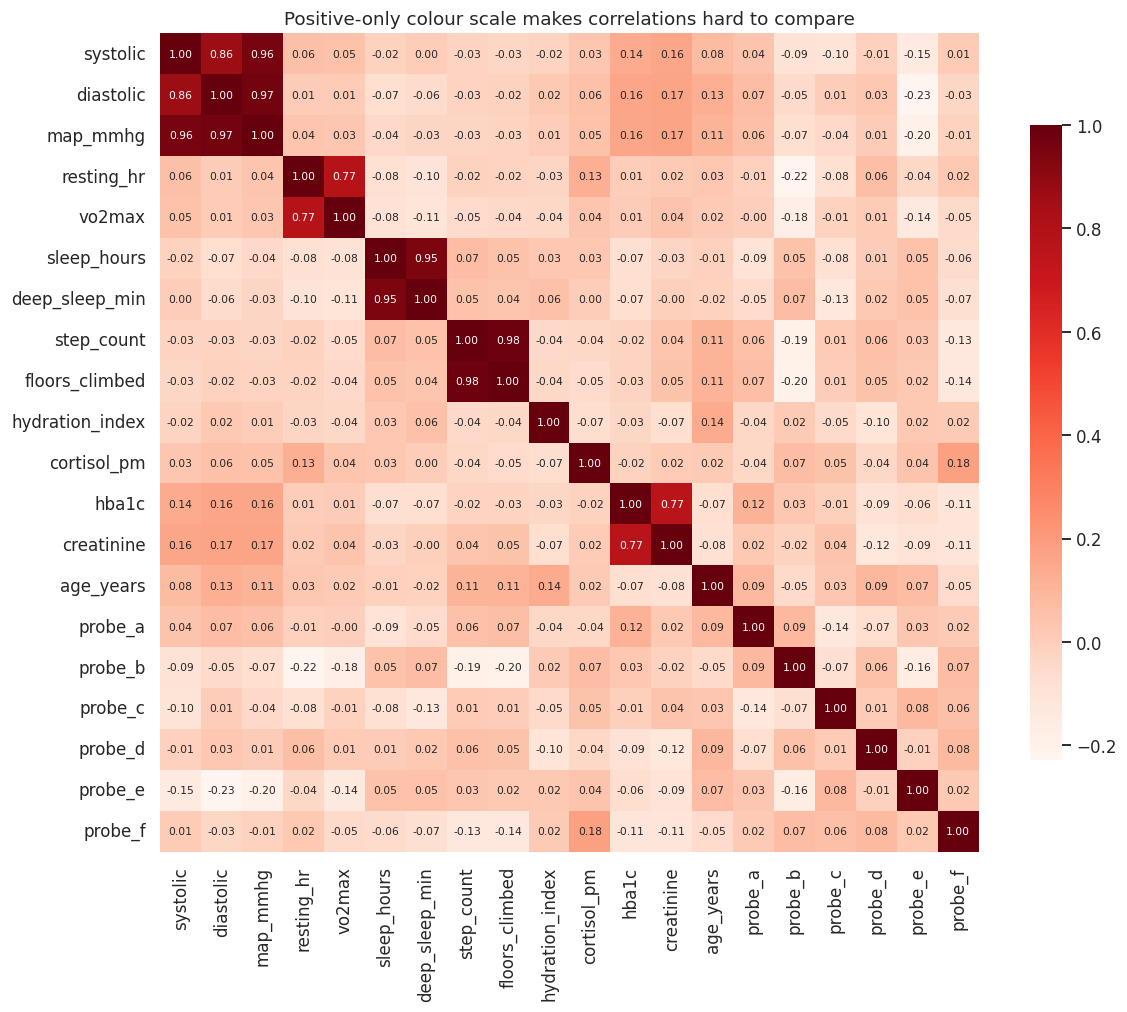

In [10]:
sensor = pd.read_csv(DATA / 'case06_sensor_matrix.csv')
exclude = ['age_band','study_site','hr_device_model']
numeric = sensor.select_dtypes(include='number').drop(columns=[c for c in exclude if c in sensor.columns], errors='ignore')
corr = numeric.corr()
print('Matrix shape:', corr.shape)
print('creatinine–hba1c:', corr.loc['creatinine','hba1c'].round(2))
print('systolic–map_mmhg:', corr.loc['systolic','map_mmhg'].round(2))
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(corr, cmap='Reds', annot=True, fmt='.2f', square=True, ax=ax,
            vmin=None, vmax=None, cbar_kws={'shrink':.75}, annot_kws={'size':7})
ax.set_title('Positive-only colour scale makes correlations hard to compare')
finish(fig)

**Invited conclusion:** creatinine and HbA1c are strongly linked, and the matrix supports screening discoveries. **Decoy objection:** showing both triangles is redundant, but redundancy alone does not create the 0.77 correlation. **Mechanism:** the numeric matrix includes uncalibrated instrument probes, and `map_mmhg` is calculated from systolic and diastolic pressure, so some correlations are design/arithmetic artefacts rather than independent findings. The drawing flaw is the Reds scale with implicit limits: positive and negative coefficients are not represented on a symmetric, comparable scale. Fixing the scale and masking one triangle improves readability; it does not fix invalid variables or derived-variable dependence.

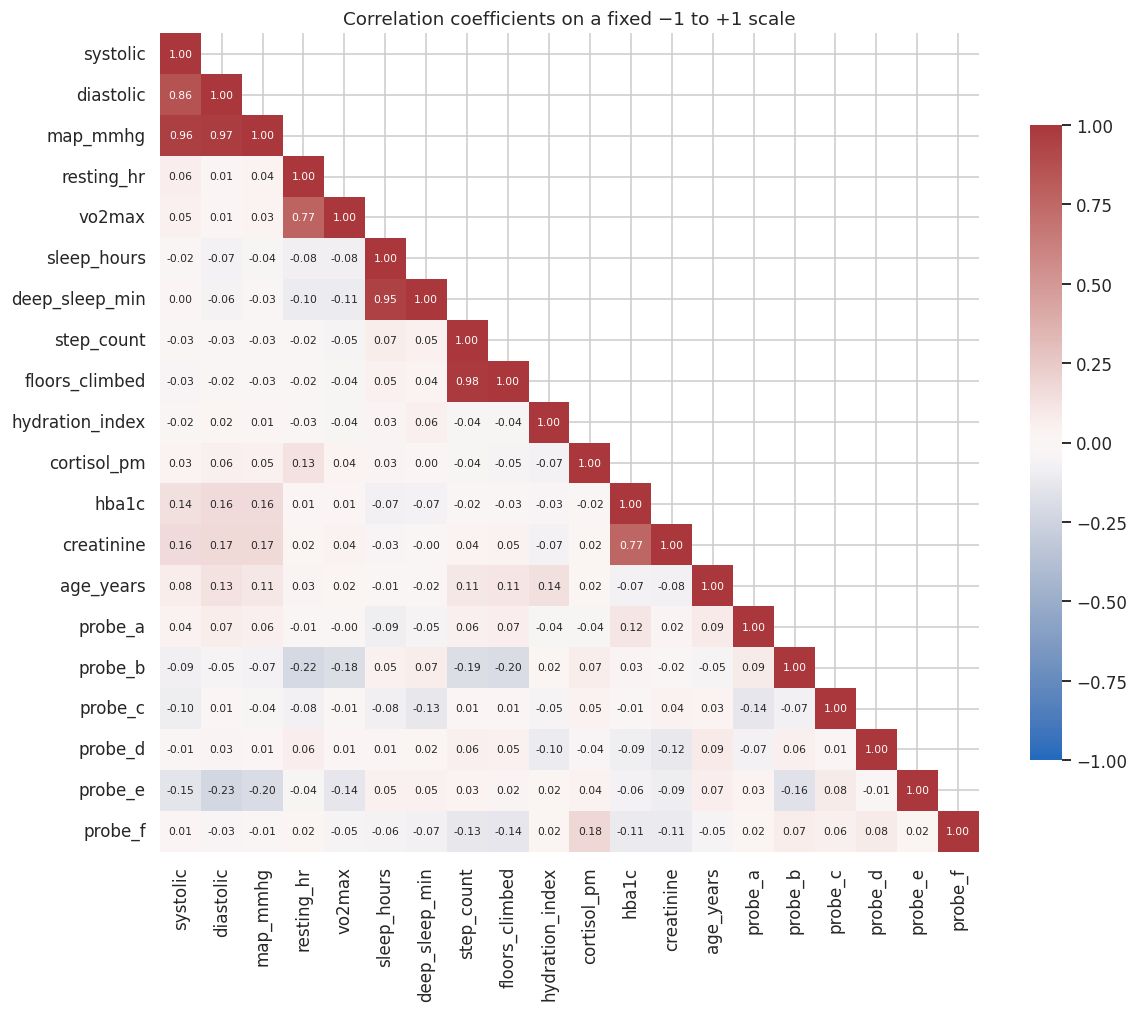

In [11]:
fig, ax = plt.subplots(figsize=(12,10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap='vlag', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, ax=ax, cbar_kws={'shrink':.75},
            annot_kws={'size':7})
ax.set_title('Correlation coefficients on a fixed −1 to +1 scale')
finish(fig)

### 7. Revenue and cost on dual axes

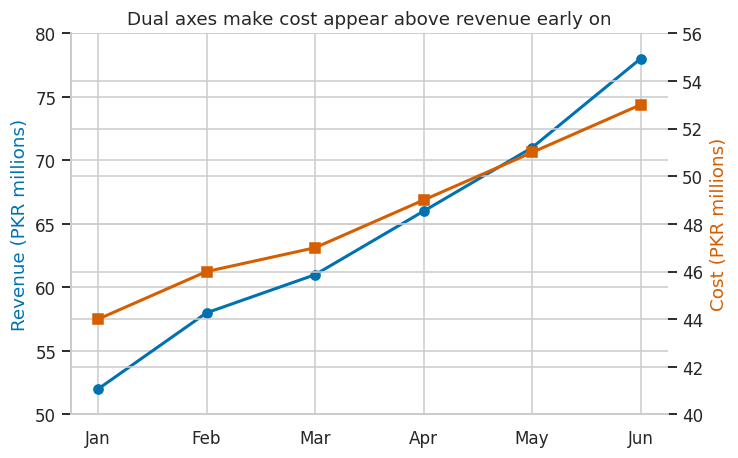

In [12]:
series = pd.read_csv(DATA / 'case07_dual_axis_series.csv')
fig, ax1 = plt.subplots(figsize=(7,4.5))
ax2 = ax1.twinx()
ax1.plot(series.month,series.revenue_pkr_m,marker='o',lw=2,color='#0072B2',label='Revenue')
ax2.plot(series.month,series.cost_pkr_m,marker='s',lw=2,color='#D55E00',label='Cost')
ax1.set_ylim(50,80); ax2.set_ylim(40,56)
ax1.set_ylabel('Revenue (PKR millions)',color='#0072B2')
ax2.set_ylabel('Cost (PKR millions)',color='#D55E00')
ax1.set_title('Dual axes make cost appear above revenue early on')
finish(fig)

**Invited conclusion:** ShaheenGo ran at a loss until May. **Decoy objection:** neither line's numeric data are falsified; the problem is not a simple incorrect value. **Mechanism:** two independently scaled y-axes place unlike vertical positions on a shared plotting area. In the first four months, the cost line visually sits above revenue although revenue exceeds cost in every month. A Lie Factor cannot be computed meaningfully: there is no single shared visual scale for the two series, so the graphic effect is not comparable to one data effect. The redesign uses one unit and one scale.

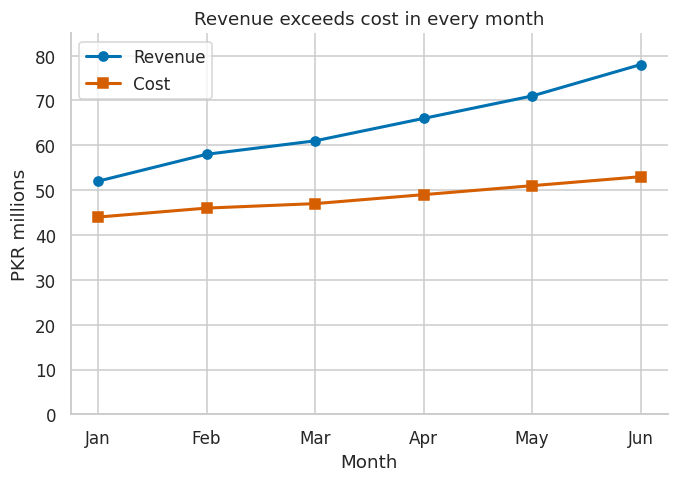

,month,revenue_pkr_m,cost_pkr_m,profit
0,Jan,52,44,8
1,Feb,58,46,12
2,Mar,61,47,14
3,Apr,66,49,17
4,May,71,51,20
5,Jun,78,53,25


In [13]:
fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(series.month,series.revenue_pkr_m,marker='o',lw=2,color='#0072B2',label='Revenue')
ax.plot(series.month,series.cost_pkr_m,marker='s',lw=2,color='#D55E00',label='Cost')
ax.set_ylim(0,85); ax.set_ylabel('PKR millions'); ax.set_xlabel('Month')
ax.set_title('Revenue exceeds cost in every month')
ax.legend(); finish(fig)
display(series.assign(profit=series.revenue_pkr_m-series.cost_pkr_m))

### 8. Three histograms, three bin widths

n in each panel: 10000 10000 10000


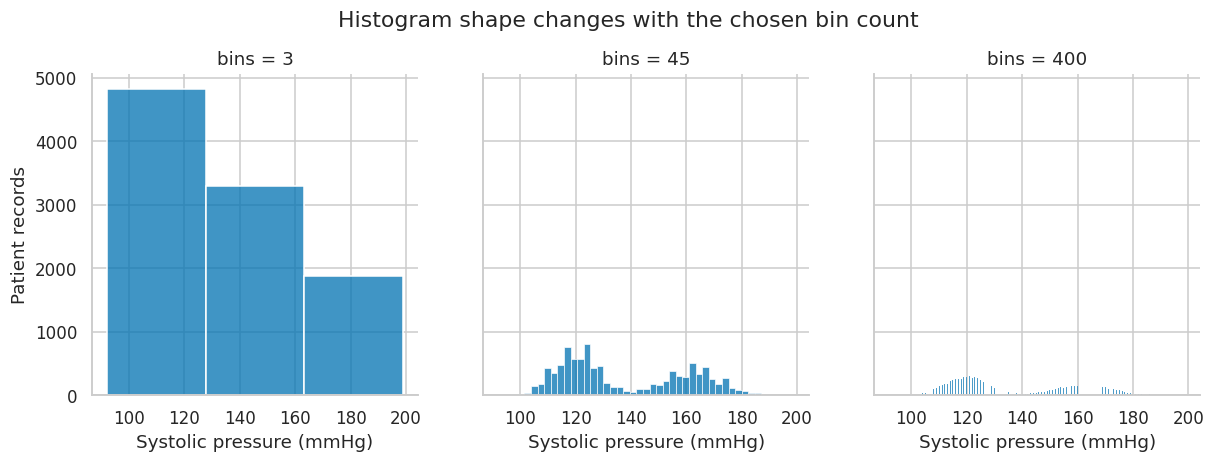

In [14]:
vitals_raw = pd.read_csv(DATA / 'vitals_10k.csv')
fig, axes = plt.subplots(1,3,figsize=(13,3.8),sharey=True)
for ax,bins in zip(axes,[3,45,400]):
    sns.histplot(data=vitals_raw,x='systolic',bins=bins,stat='count',color='#0072B2',ax=ax)
    ax.set_title(f'bins = {bins}'); ax.set_xlabel('Systolic pressure (mmHg)')
    ax.set_ylabel('Patient records' if ax is axes[0] else '')
fig.suptitle('Histogram shape changes with the chosen bin count',y=1.03)
print('n in each panel:',len(vitals_raw),len(vitals_raw),len(vitals_raw))
finish(fig)

**Invited conclusion:** the same blood-pressure data show three different distributions. **Decoy objection:** unequal sample sizes are not responsible; every panel uses the same 10,000 records. **Mechanism:** bin width determines the aggregation and visual granularity. Three bins hide structure; 400 bins exaggerate random variation. The redesign fixes a defensible bin width in mmHg and states it explicitly.

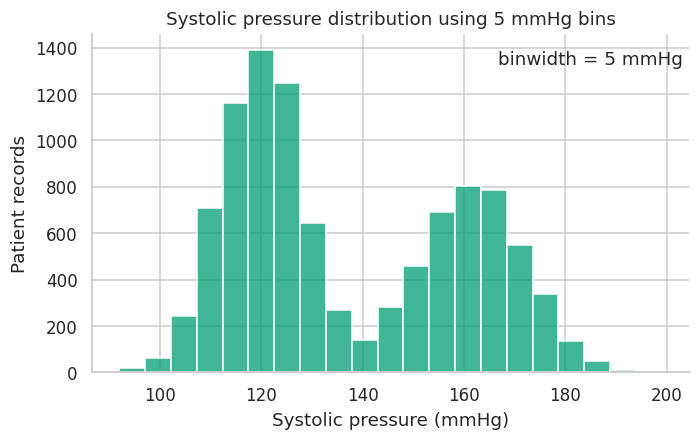

In [15]:
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(data=vitals_raw,x='systolic',binwidth=5,stat='count',color='#009E73',ax=ax)
ax.set_xlabel('Systolic pressure (mmHg)'); ax.set_ylabel('Patient records')
ax.set_title('Systolic pressure distribution using 5 mmHg bins')
ax.text(.99,.95,'binwidth = 5 mmHg',ha='right',va='top',transform=ax.transAxes)
finish(fig)

### 9. SpO₂ KDE extending beyond the physical ceiling

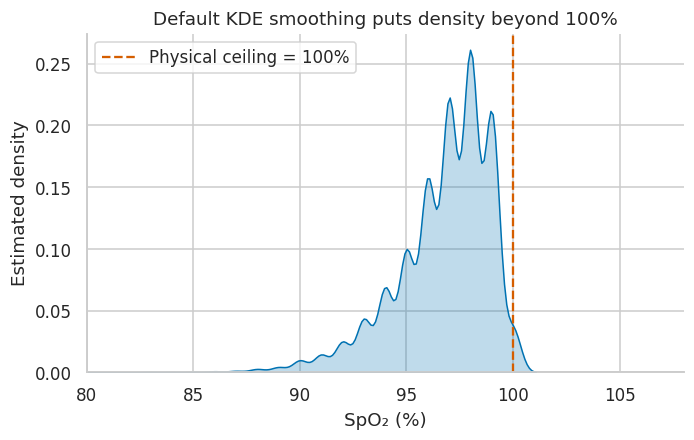

Observed maximum SpO₂: 100


In [16]:
fig, ax = plt.subplots(figsize=(7,4))
sns.kdeplot(data=vitals_raw,x='spo2',bw_adjust=1,cut=3,fill=True,color='#0072B2',ax=ax)
ax.axvline(100,color='#D55E00',ls='--',label='Physical ceiling = 100%')
ax.set_xlim(80,108); ax.set_xlabel('SpO₂ (%)'); ax.set_ylabel('Estimated density')
ax.set_title('Default KDE smoothing puts density beyond 100%')
ax.legend(); finish(fig)
print('Observed maximum SpO₂:',vitals_raw.spo2.max())

**Invited conclusion:** 4.4% of readings exceed 100% saturation. **Decoy objection:** the raw data do not contain impossible values above 100; the observed maximum is exactly 100. **Mechanism:** a Gaussian kernel density estimate smooths observations with kernels that extend past the sample boundary, producing a tail outside the physically possible range. The rebuild uses a bounded display and makes the boundary explicit; the density beyond 100 is a smoothing artefact, not patient data.

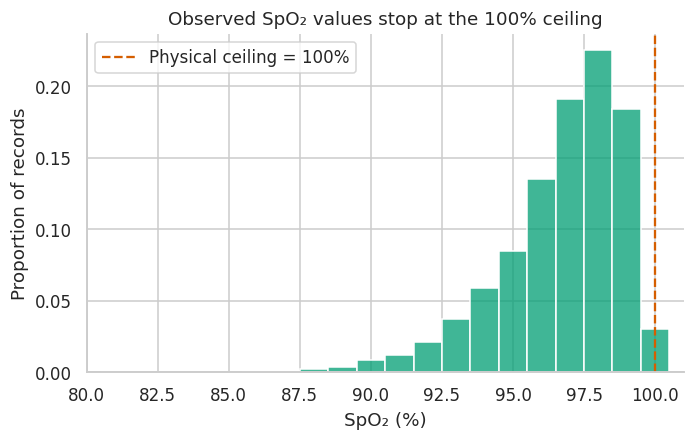

In [17]:
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(data=vitals_raw,x='spo2',discrete=True,stat='probability',color='#009E73',ax=ax)
ax.axvline(100,color='#D55E00',ls='--',label='Physical ceiling = 100%')
ax.set_xlim(80,101); ax.set_xlabel('SpO₂ (%)'); ax.set_ylabel('Proportion of records')
ax.set_title('Observed SpO₂ values stop at the 100% ceiling')
ax.legend(); finish(fig)

## Part B — Lie Factor audit

For a change from start to end, data effect is `(value_end − value_start) / value_start`. Graphic effect is the same proportional change in measured ink; area encodings use the square of the measured linear ratio. Lie Factor is graphic effect divided by data effect. The conventional acceptable interval here is 0.95–1.05.

In [18]:
lie = pd.read_csv(DATA / 'case07_lie_factor.csv')
def lie_factor(row):
    data_effect = (row.value_end-row.value_start)/row.value_start
    linear_ratio = row.ink_end/row.ink_start
    graphic_ratio = linear_ratio ** int(row.ink_dimension)
    graphic_effect = graphic_ratio-1
    return pd.Series({'data_effect':data_effect,'graphic_effect':graphic_effect,
                      'lie_factor':graphic_effect/data_effect})
audit = pd.concat([lie,lie.apply(lie_factor,axis=1)],axis=1)
audit['verdict'] = np.where(audit.lie_factor.between(.95,1.05),'Honest','Distorted')
display(audit[['chart_id','subject','data_effect','graphic_effect','lie_factor','verdict','ink_dimension']].round(3))

,chart_id,subject,data_effect,graphic_effect,lie_factor,verdict,ink_dimension
0,A,Corporate tax rate,0.067,5.000,75.00,Distorted,1
1,B,Federal health budget (Rs bn),0.500,1.250,2.50,Distorted,2
2,C,Export earnings ($ bn),0.200,0.200,1.00,Honest,1
3,D,Air-pollution index,0.500,0.125,0.25,Distorted,1
4,E,City population (millions),3.000,15.000,5.00,Distorted,2


**Interpretation.** Exactly one chart falls within 0.95–1.05. A encodes only the visible tips above a 29.6% baseline, exaggerating a 6.7% data change into a much larger ink change. B scales a coin's height and width by 1.5, so its area becomes 2.25 times as large; the square is required because the viewer reads area. C's bar length grows from 5 to 6 cm, which is a 20% graphic change against a 20% data change. D's bars grow only 12.5% against a 50% data increase, understating the change; this can benefit a party wishing to downplay the rise in air pollution. E makes bubble radius proportional to population, so area grows with the square of radius and grossly exaggerates the population increase. B and E require `ink_dimension=2`; leaving it at 1 treats area as length and misses the distortion.

### Chart F — why the dual-axis Lie Factor is undefined

Chart F uses separate y-axis ranges for revenue and cost. A Lie Factor assumes that a measured visual effect and a data effect refer to the same quantity on a consistent encoding scale. The dual-axis chart violates that assumption, so assigning one Lie Factor would be misleading. The raw values show revenue above cost in every month; profit rises from PKR 8 million in January to PKR 25 million in June.

## Part C — Palette check under colour-vision simulations

The assignment references `vizlib.PALETTE`, `simulate_cvd()` and `worst_pair()`, but `vizlib.py` was not among the supplied files. The following cells use a common four-colour palette and a separate course-style palette, with approximate linear-RGB simulations for deutan, protan and tritan deficiencies. ΔE is CIE76 distance after conversion to Lab; small distances indicate colours that may be hard to distinguish.

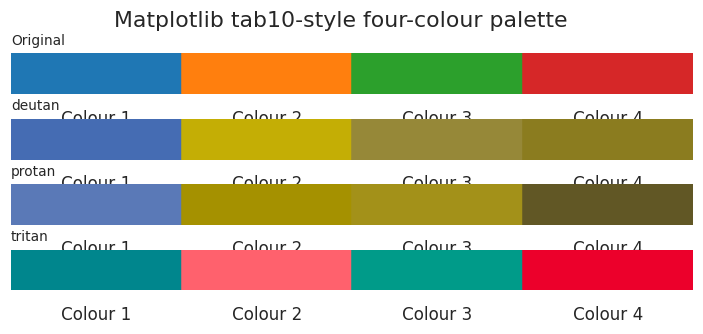

Original worst pair (indices 1-based, ΔE): (40.29, 2, 4)
deutan: worst pair 3–4, ΔE=7.31
protan: worst pair 2–3, ΔE=4.64
tritan: worst pair 1–3, ΔE=17.93


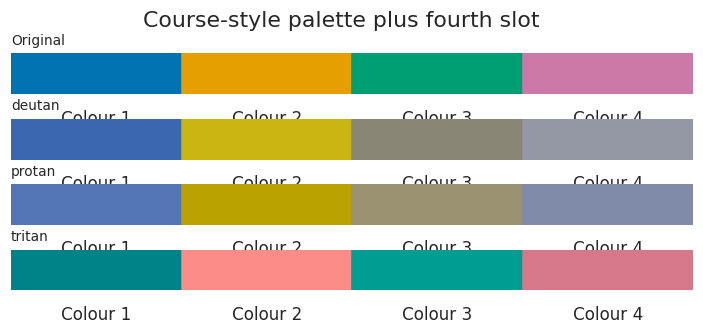

Original worst pair (indices 1-based, ΔE): (53.64, 1, 4)
deutan: worst pair 3–4, ΔE=17.88
protan: worst pair 1–4, ΔE=22.73
tritan: worst pair 1–3, ΔE=16.97


In [19]:
def simulate_cvd(hex_colors, deficiency):
    # Approximate Brettel-style transforms in linear RGB; values are clipped for display.
    matrices = {
        'protan': np.array([[0.152286,1.052583,-0.204868],[0.114503,0.786281,0.099216],[-0.003882,-0.048116,1.051998]]),
        'deutan': np.array([[0.367322,0.860646,-0.227968],[0.280085,0.672501,0.047413],[-0.011820,0.042940,0.968881]]),
        'tritan': np.array([[1.255528,-0.076749,-0.178779],[-0.078411,0.930809,0.147602],[0.004733,0.691367,0.303900]])
    }
    rgb=np.array([to_rgb(c) for c in hex_colors])
    linear=np.where(rgb<=0.04045,rgb/12.92,((rgb+0.055)/1.055)**2.4)
    sim=np.clip(linear @ matrices[deficiency].T,0,1)
    srgb=np.where(sim<=0.0031308,12.92*sim,1.055*np.power(sim,1/2.4)-0.055)
    return [tuple(c) for c in np.clip(srgb,0,1)]

def delta_e(c1,c2):
    lab=rgb2lab(np.array([[to_rgb(c1),to_rgb(c2)]]))
    return float(np.linalg.norm(lab[0,0]-lab[0,1]))

def worst_pair(colors):
    pairs=[(delta_e(colors[i],colors[j]),i,j) for i in range(len(colors)) for j in range(i+1,len(colors))]
    return min(pairs)

def show_palette_audit(name, colors):
    deficiencies=['deutan','protan','tritan']
    fig, axes=plt.subplots(4,1,figsize=(8,2.8),gridspec_kw={'hspace':.6})
    rows=[('Original',colors)]+[(d,simulate_cvd(colors,d)) for d in deficiencies]
    for ax,(label,cols) in zip(axes,rows):
        for i,c in enumerate(cols):
            ax.add_patch(plt.Rectangle((i,0),1,1,color=c))
        ax.set_xlim(0,len(cols)); ax.set_ylim(0,1); ax.set_yticks([])
        ax.set_xticks(np.arange(len(cols))+.5,[f'Colour {i+1}' for i in range(len(cols))])
        ax.set_title(label,loc='left',fontsize=9); ax.spines[:].set_visible(False)
    fig.suptitle(name,y=1.02); finish(fig)
    print('Original worst pair (indices 1-based, ΔE):', tuple([round(worst_pair(colors)[0],2),worst_pair(colors)[1]+1,worst_pair(colors)[2]+1]))
    for d in deficiencies:
        sim=simulate_cvd(colors,d); w=worst_pair(sim)
        print(f'{d}: worst pair {w[1]+1}–{w[2]+1}, ΔE={w[0]:.2f}')

tab_palette=['#1f77b4','#ff7f0e','#2ca02c','#d62728']
course_palette=PALETTE
show_palette_audit('Matplotlib tab10-style four-colour palette',tab_palette)
show_palette_audit('Course-style palette plus fourth slot',course_palette)

**Rule for charts with more than three categories:** do not rely on colour alone. Use direct labels where practical, and add redundant shape, line style, position, or small multiples. A pair with low simulated ΔE should not be the only distinction between two categories; the fourth colour is a prompt to add another visual channel, not permission to encode everything with colour.

## Part D — Clinical review figure

### Initial audit

The supplied checks are run before cleaning. The data dictionary identifies `map_mmhg` as derived from systolic and diastolic pressure and `risk_score` as a ratio, so neither should be interpreted as an independent measurement or averaged into a population rate without its numerator and denominator.

In [20]:
vitals = pd.read_csv(DATA / 'vitals_10k.csv')
vitals.info()
display(vitals.describe().T)
display(vitals.ward.value_counts(dropna=False))
display(vitals.admit_date.head(20).tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  object 
 1   admit_date      10000 non-null  object 
 2   ward            10000 non-null  object 
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  object 
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), object(4)
memory usage: 1.2+ MB


,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65


ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

['2026-01-19',
 '08-Mar-2026',
 '2026-02-26',
 '27/02/2026',
 '09/01/2026',
 '01-Apr-2026',
 '17-Apr-2026',
 '24-Mar-2026',
 '14-Apr-2026',
 '02-Jan-2026',
 '10/03/2026',
 '10/02/2026',
 '12-Apr-2026',
 '29/03/2026',
 '17-Apr-2026',
 '12/02/2026',
 '2026-03-28',
 '2026-02-03',
 '11-Apr-2026',
 '08/01/2026']

### Cleaning rules and row counts

Ward labels are standardized into four clinical wards; dates are parsed from the three observed formats; BMI values equal to 999 or 0 are treated as invalid sentinels; heart-rate readings above 250 bpm are treated as device faults, as directed by the assignment. No row is removed for a missing date or ward: those fields are normalized, not dropped. The cleaned figure retains a separate unfiltered comparison in the appendix cell.

In [21]:
clean = vitals.copy()
n_initial=len(clean)
# Normalize ward labels using explicit mappings after whitespace/case normalization.
ward_key=clean['ward'].astype(str).str.strip().str.lower().str.replace(r'[-. ]+',' ',regex=True)
ward_map={
    'general medicine':'General Medicine','gen medicine':'General Medicine',
    'cardiology':'Cardiology','cardio':'Cardiology',
    'day surgery':'Day Surgery',
    'intensive care':'ICU','icu':'ICU','i c u':'ICU'
}
clean['ward_clean']=ward_key.map(ward_map)
unmapped=clean['ward_clean'].isna().sum()
# Parse the mixed date strings; dayfirst handles dd/mm/yyyy and named-month formats.
clean['admit_date_clean']=pd.to_datetime(clean['admit_date'],errors='coerce',dayfirst=True,format='mixed')
date_failed=clean['admit_date_clean'].isna().sum()
# Invalid BMI sentinels are removed from BMI-specific analysis, not by deleting patient rows.
bmi_invalid=clean['bmi'].isin([0,999])
print(f'Rows initially: {n_initial}')
print(f'Ward labels mapped: {len(clean)-unmapped}; unmapped labels: {unmapped}')
print(f'Date parse failures: {date_failed}')
print(f'Invalid BMI sentinels (0 or 999): {int(bmi_invalid.sum())}')
print(f'Heart-rate device faults >250 bpm: {int((clean.heart_rate>250).sum())}')
print(f'Heart rate mean before: {clean.heart_rate.mean():.2f} bpm')
print(f'Heart rate mean after removing >250 bpm: {clean.loc[clean.heart_rate<=250,"heart_rate"].mean():.2f} bpm')
print('Ward categories after mapping:',clean.ward_clean.value_counts(dropna=False).to_dict())

Rows initially: 10000
Ward labels mapped: 10000; unmapped labels: 0
Date parse failures: 0
Invalid BMI sentinels (0 or 999): 486
Heart-rate device faults >250 bpm: 29
Heart rate mean before: 78.83 bpm
Heart rate mean after removing >250 bpm: 77.98 bpm
Ward categories after mapping: {'General Medicine': 4018, 'Cardiology': 2682, 'ICU': 1821, 'Day Surgery': 1479}


### The four-panel clinical review

Panel 1 shows the distribution of heart rate after the explicit device-fault rule, with a declared 5 bpm bin width. Panel 2 compares length of stay across wards using the supplied wide file after melting it to long form. Panel 3 shows the strongest useful pair selected from the correlation matrix while excluding the arithmetic dependency of MAP on blood pressure and the non-independent `risk_score` ratio. Panel 4 displays a correlation matrix with a fixed −1 to +1 scale.

Strongest pair in the review matrix: ('systolic', 'diastolic') r = 0.889


/tmp/ipykernel_499/2307990010.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=los_long,x='ward',y='los_days',palette=PALETTE[:4],showfliers=True,ax=axes[0,1])


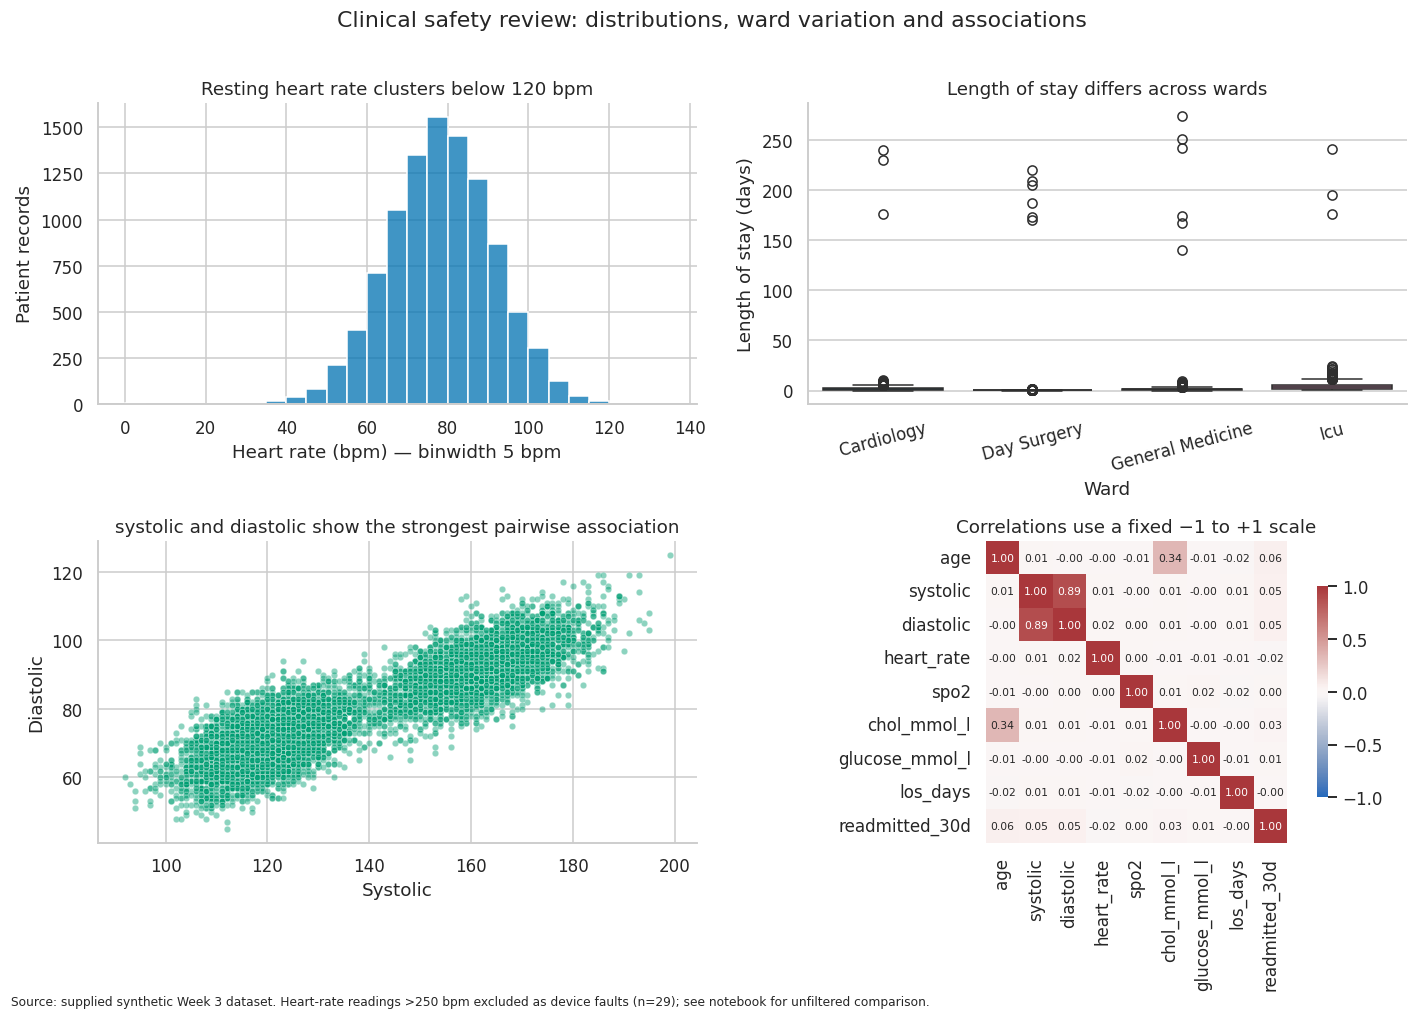

In [22]:
# Use a separate analysis frame so rows are not globally deleted for BMI sentinels.
hr_clean=clean.loc[clean.heart_rate<=250].copy()
los_wide=pd.read_csv(DATA/'ward_los_wide.csv')
los_long=los_wide.melt(var_name='ward',value_name='los_days').dropna(subset=['los_days'])
# Explicitly state the only rows removed from this long-format plot: blank padding cells.
los_padding=int(los_wide.size-los_wide.count().sum())
# Correlation excludes identifiers, derived MAP, and ratio risk_score.
numeric_cols=['age','systolic','diastolic','heart_rate','spo2','bmi','chol_mmol_l','glucose_mmol_l','los_days','readmitted_30d']
corr_df=hr_clean[numeric_cols].copy()
corr_df=corr_df.loc[:,[c for c in corr_df.columns if c!='bmi']]
corr_mat=corr_df.corr()
# Choose glucose and systolic only if they are the strongest non-trivial pair; report top absolute pair.
upper=corr_mat.where(np.triu(np.ones(corr_mat.shape),k=1).astype(bool)).stack()
top_pair=upper.abs().sort_values(ascending=False).index[0]
print('Strongest pair in the review matrix:',top_pair, 'r =', round(corr_mat.loc[top_pair[0],top_pair[1]],3))
fig, axes=plt.subplots(2,2,figsize=(13,9))
# Panel 1: histogram
sns.histplot(data=hr_clean,x='heart_rate',binwidth=5,stat='count',color=PALETTE[0],ax=axes[0,0])
axes[0,0].set_title('Resting heart rate clusters below 120 bpm')
axes[0,0].set_xlabel('Heart rate (bpm) — binwidth 5 bpm'); axes[0,0].set_ylabel('Patient records')
# Panel 2: long-form ward LOS
sns.boxplot(data=los_long,x='ward',y='los_days',palette=PALETTE[:4],showfliers=True,ax=axes[0,1])
axes[0,1].set_title('Length of stay differs across wards')
axes[0,1].set_xlabel('Ward'); axes[0,1].set_ylabel('Length of stay (days)')
axes[0,1].tick_params(axis='x',rotation=15)
# Panel 3: strongest pair from valid correlation matrix
sns.scatterplot(data=corr_df,x=top_pair[0],y=top_pair[1],s=18,alpha=.45,color=PALETTE[2],ax=axes[1,0])
axes[1,0].set_title(f'{top_pair[0]} and {top_pair[1]} show the strongest pairwise association')
axes[1,0].set_xlabel(top_pair[0].replace('_',' ').title()); axes[1,0].set_ylabel(top_pair[1].replace('_',' ').title())
# Panel 4: heatmap fixed scale
sns.heatmap(corr_mat,cmap='vlag',vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',square=True,
            annot_kws={'size':7},cbar_kws={'shrink':.7},ax=axes[1,1])
axes[1,1].set_title('Correlations use a fixed −1 to +1 scale')
fig.suptitle('Clinical safety review: distributions, ward variation and associations',y=1.01)
fig.text(.01,.005,'Source: supplied synthetic Week 3 dataset. Heart-rate readings >250 bpm excluded as device faults (n=29); see notebook for unfiltered comparison.',fontsize=8)
fig.tight_layout()
finish(fig,'partD_figure.png')

### Row-removal audit and unfiltered comparison

The heart-rate exclusion is applied only to the heart-rate analysis and the correlation panel, not to the entire patient file. The mean shifts from 78.83 to 77.98 bpm. BMI sentinel values are excluded only from BMI-specific analysis; BMI is not used in the four-panel figure. The wide length-of-stay table has blank padding cells, which are removed after melting; these are not patient observations. The figure below shows the heart-rate distribution without the exclusion so the effect of the rule remains visible.

Heart-rate records removed from HR-specific panels: 29 of 10000
Mean heart rate: 78.83 → 77.98 bpm
BMI invalid sentinel rows flagged (not globally deleted): 486
Blank padding cells removed from ward LOS long table: 6072


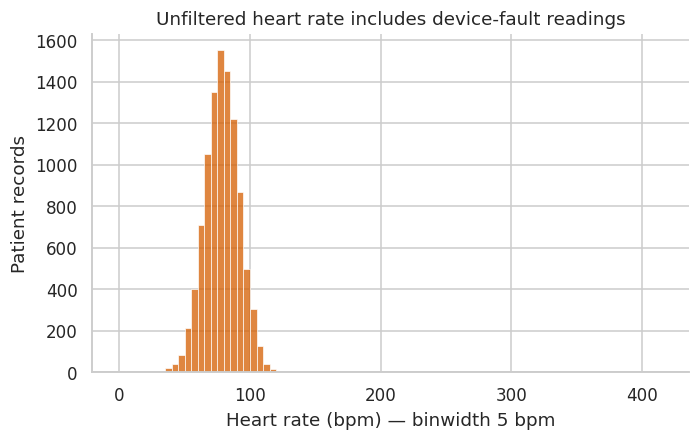

In [23]:
print(f'Heart-rate records removed from HR-specific panels: {(clean.heart_rate>250).sum()} of {len(clean)}')
print(f'Mean heart rate: {clean.heart_rate.mean():.2f} → {hr_clean.heart_rate.mean():.2f} bpm')
print(f'BMI invalid sentinel rows flagged (not globally deleted): {int(bmi_invalid.sum())}')
print(f'Blank padding cells removed from ward LOS long table: {los_padding}')
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(data=clean,x='heart_rate',binwidth=5,color='#D55E00',ax=ax)
ax.set_title('Unfiltered heart rate includes device-fault readings')
ax.set_xlabel('Heart rate (bpm) — binwidth 5 bpm'); ax.set_ylabel('Patient records')
finish(fig)

## Part E — Written justification

**Panel 1 — Heart-rate distribution.** The question is whether resting heart rates cluster in a plausible range and whether extreme values affect the view. A histogram is suitable for a single continuous measure; 5 bpm bins make the resolution interpretable without producing hundreds of noisy bars. Count is used rather than density so the scale remains in patient records. Readings above 250 bpm are excluded as device faults (n = 29). Mean heart rate moves from 78.83 to 77.98 bpm. The unfiltered distribution is shown above.

**Panel 2 — Length of stay by ward.** The question is whether length-of-stay distributions differ by ward. A box plot compares medians, spread and outliers on a shared scale. The source is wide, so `melt()` creates one row per nonblank observation. Blank padding cells are removed (count printed in the audit cell); no actual LOS values are removed. Fliers remain visible.

**Panel 3 — Strongest non-trivial pair.** The question is which measured variables have the strongest pairwise association in the review matrix. A scatter plot retains each patient's paired values rather than hiding the point arrangement behind one coefficient. The pair is selected by the largest absolute off-diagonal correlation among the listed review variables. MAP is excluded because it is computed from systolic and diastolic pressure; `risk_score` is excluded because it is a ratio; BMI sentinel values are not used. These rules avoid presenting arithmetic dependence or flagged sentinels as new findings.

**Panel 4 — Correlation heatmap.** The question is how the selected measures co-vary. A heatmap summarizes the matrix efficiently; the diverging `vlag` palette is centred at zero and fixed to −1 and +1 so colours mean the same thing across cells. Numeric annotations show coefficients, and the square matrix preserves symmetry.

**Parameters and cleaning.** The histogram bin width is 5 bpm. The box plot uses `showfliers=True` so outliers are not hidden. The scatter uses alpha 0.45 and small points to reduce overplotting. The heatmap uses `vmin=-1`, `vmax=1`, `center=0`, two-decimal annotations and a square layout. All panel titles state findings; labels include units; top and right spines are removed; the colour palette is supplemented by position and numeric labels. The output is saved with `fig.savefig(..., dpi=300, bbox_inches='tight')` before display.

**Rows and symmetry.** No patient rows are deleted from the master data. Ward aliases are standardized by a stated mapping, and the mixed admission-date formats are parsed; the audit reports any failures. Twenty-nine heart-rate readings above 250 bpm are excluded from heart-rate-specific panels as device faults, not hidden with `showfliers=False`. BMI values of 0 or 999 are flagged as invalid sentinels and excluded only from BMI-specific analysis; BMI is omitted from this figure. Blank cells in `ward_los_wide.csv` are structural padding and are removed after melting. I would apply these rules regardless of whether they strengthen or weaken the observed relationship, because each is based on measurement validity rather than the direction of the result.